# MINDTRACE — MentalBERT Full-Scale Reproduction (Google Colab Free Tier)

**Authoritative Source**: `notebooks/text_model.ipynb`  
**Dataset**: `sentiment_mental_health.csv` (52,680 verified clean records)  
**Target Hardware**: Free Google Colab **Tesla T4 GPU** (15 GB VRAM)  
**Expected Runtime**: ~50 minutes total (~16.7 minutes per epoch)  

### Historical Recorded Benchmark Targets:
- **Test Accuracy**: **84.26%**
- **Macro F1**: **82.90%**
- **Weighted F1**: **84.21%**
- **Suicidal-Class Recall**: **71.0%** (Precision: 75%, F1: 73%)

---

In [1]:
import os

path = "/content/sentiment_mental_health.csv"

print("Dataset exists:", os.path.exists(path))

if os.path.exists(path):
    print("File size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

Dataset exists: False


In [2]:
# CELL 1 — Install Dependencies (Free Standard Libraries)
!pip install -q transformers torch scikit-learn pandas numpy datasets matplotlib seaborn

KeyboardInterrupt: 

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "sentiment_mental_health.csv" in files:
        print("FOUND:", os.path.join(root, "sentiment_mental_health.csv"))

FOUND: /content/drive/MyDrive/MINDTRACE_DATA/sentiment_mental_health.csv


In [4]:
import pandas as pd

path = "/content/drive/MyDrive/MINDTRACE_DATA/sentiment_mental_health.csv"

df = pd.read_csv(path, encoding="latin-1")

print("Raw shape:", df.shape)
print("Clean records:", len(df.dropna(subset=["statement", "status"])))
print("\nClass distribution:")
print(df.dropna(subset=["statement", "status"])["status"].value_counts())

Raw shape: (53044, 3)
Clean records: 52680

Class distribution:
status
Normal                  16343
Depression              15404
Suicidal                10651
Anxiety                  3841
Bipolar                  2777
Stress                   2587
Personality disorder     1077
Name: count, dtype: int64


In [5]:
import os

path = "/content/drive/MyDrive/MINDTRACE_DATA/sentiment_mental_health.csv"

print("Drive dataset exists:", os.path.exists(path))
print("Drive dataset size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

Drive dataset exists: True
Drive dataset size: 30.06 MB


In [ ]:
# CELL 2 — Check Compute Environment (Free T4 GPU)
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Compute Device:', device)

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
    print(f'GPU Detected: {gpu_name} ({vram_gb} GB VRAM)')
    print('Ready for full-scale MentalBERT training.')
else:
    print('WARNING: Running on CPU! Enable free T4 GPU under Runtime > Change runtime type > T4 GPU.')

Compute Device: cuda
GPU Detected: Tesla T4 (15.64 GB VRAM)
Ready for full-scale MentalBERT training.


In [ ]:
# CELL 3 — Optional: Mount Google Drive for Persistent Checkpoint Saving
import os
import shutil

DRIVE_MOUNTED = False
CHECKPOINT_DIR = './checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DIR = '/content/drive/MyDrive/MINDTRACE_checkpoints'
    os.makedirs(DRIVE_DIR, exist_ok=True)
    DRIVE_MOUNTED = True
    print(f'Google Drive mounted successfully. Checkpoints will sync to: {DRIVE_DIR}')
except Exception as e:
    print(f'Google Drive not mounted ({e}). Checkpoints will save to local Colab storage ({CHECKPOINT_DIR}).')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully. Checkpoints will sync to: /content/drive/MyDrive/MINDTRACE_checkpoints


In [ ]:
# CELL 4 — Optional Hugging Face Hub Authentication (Secure & Non-blocking)
from huggingface_hub import login

hf_token = None
try:
    from google.colab import userdata
    hf_token = userdata.get('HF_TOKEN') or userdata.get('Hugging_face')
except Exception:
    pass

if hf_token:
    try:
        login(token=hf_token)
        print('Authenticated with Hugging Face Hub via Colab Secret.')
    except Exception as e:
        print(f'Login notice: {e}. Proceeding with unauthenticated public access.')
        hf_token = None
else:
    print('No Colab Secret HF_TOKEN detected. Proceeding with standard unauthenticated public access.')
    hf_token = None

No Colab Secret HF_TOKEN detected. Proceeding with standard unauthenticated public access.


In [10]:

# CELL 5 — Load & Verify Dataset (52,680 records)

import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

csv_candidates = [
    '/content/drive/MyDrive/MINDTRACE_DATA/sentiment_mental_health.csv',
    'sentiment_mental_health.csv',
    '/content/sentiment_mental_health.csv',
    '/content/drive/MyDrive/sentiment_mental_health.csv',
    '/content/drive/MyDrive/MINDTRACE/sentiment_mental_health.csv',
    'data/raw/sentiment_mental_health.csv'
]

csv_path = None
for path in csv_candidates:
    if os.path.exists(path):
        csv_path = path
        break

if csv_path:
    print(f'Loading verified original dataset from: {csv_path} (encoding=latin-1)...')
    df_raw = pd.read_csv(csv_path, encoding='latin-1')
else:
    raise FileNotFoundError(
        "Verified CSV not found. Please check Google Drive mounting and dataset path."
    )

print(f'Raw records loaded: {len(df_raw):,}')

text_col = 'statement' if 'statement' in df_raw.columns else 'text'
label_col = 'status' if 'status' in df_raw.columns else 'label'

df_clean = pd.DataFrame({
    'text': df_raw[text_col],
    'label': df_raw[label_col]
}).dropna()

print(f'Clean records after dropna: {len(df_clean):,} (Expected: 52,680)')
assert len(df_clean) == 52680, f'Record count mismatch: {len(df_clean)} != 52680'

le = LabelEncoder()
df_clean['label_encoded'] = le.fit_transform(df_clean['label'])
class_names = list(le.classes_)

print('\nVerified 7-Class Distribution:')
for idx, name in enumerate(class_names):
    count = (df_clean['label'] == name).sum()
    print(f'  {idx} -> {name:22s}: {count:6,} ({count/len(df_clean)*100:.2f}%)')

X = [
    str(x).strip() if x is not None and str(x).strip() else 'empty'
    for x in df_clean['text']
]
y = df_clean['label_encoded'].tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print('\nSplits Verified:')
print(f'  Train        : {len(X_train):,} samples (Expected: 42,144)')
print(f'  Validation   : {len(X_val):,} samples (Expected: 5,268)')
print(f'  Held-out Test: {len(X_test):,} samples (Expected: 5,268)')

assert len(X_train) == 42144
assert len(X_val) == 5268
assert len(X_test) == 5268


Loading verified original dataset from: /content/drive/MyDrive/MINDTRACE_DATA/sentiment_mental_health.csv (encoding=latin-1)...
Raw records loaded: 53,044
Clean records after dropna: 52,680 (Expected: 52,680)

Verified 7-Class Distribution:
  0 -> Anxiety               :  3,841 (7.29%)
  1 -> Bipolar               :  2,777 (5.27%)
  2 -> Depression            : 15,404 (29.24%)
  3 -> Normal                : 16,343 (31.02%)
  4 -> Personality disorder  :  1,077 (2.04%)
  5 -> Stress                :  2,587 (4.91%)
  6 -> Suicidal              : 10,651 (20.22%)

Splits Verified:
  Train        : 42,144 samples (Expected: 42,144)
  Validation   : 5,268 samples (Expected: 5,268)
  Held-out Test: 5,268 samples (Expected: 5,268)


In [ ]:

# CELL 6 — Tokenize with MentalBERT + Create DataLoaders
# NOTE: hf_token is set by Cell 4 (CELL 4 — Hugging Face Authentication).
# Do NOT redefine hf_token here; it will override the authenticated value.

import torch
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader

# hf_token is defined in Cell 4 — do not reassign here.
# If this cell raises NameError for hf_token, run Cell 4 first.

MODEL_NAME = "mental/mental-bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16

print("Loading MentalBERT tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print("Tokenizer loaded successfully.")

def tokenize_batch(texts):
    return tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

print("Tokenizing training data...")
train_enc = tokenize_batch(X_train)

print("Tokenizing validation data...")
val_enc = tokenize_batch(X_val)

print("Tokenizing test data...")
test_enc = tokenize_batch(X_test)

class MentalHealthDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset = MentalHealthDataset(train_enc, y_train)
val_dataset = MentalHealthDataset(val_enc, y_val)
test_dataset = MentalHealthDataset(test_enc, y_test)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print("\nDataLoaders ready.")
print(f"Train batches      : {len(train_loader):,}")
print(f"Validation batches : {len(val_loader):,}")
print(f"Test batches       : {len(test_loader):,}")

assert len(train_loader) == 2634
assert len(val_loader) == 330
assert len(test_loader) == 330

print("All checks passed.")


In [ ]:

# ============================================================
# CELL 7 — Full 3-Epoch Training with Checkpoint Saving
# ============================================================

import os
import time
import json
import shutil
import torch

from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW

EPOCHS = 3
LR = 2e-5

# Verify GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")

if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    raise RuntimeError("GPU not detected. Stop training and enable T4 GPU.")

# Ensure checkpoint directories exist
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

if DRIVE_MOUNTED:
    os.makedirs(DRIVE_DIR, exist_ok=True)

# Load MentalBERT classification model
print("Loading MentalBERT classification model...")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(class_names),
    token=hf_token
).to(device)

optimizer = AdamW(model.parameters(), lr=LR)

# Resume support
start_epoch = 0
best_val_acc = 0.0
history = []

for ep in range(EPOCHS, 0, -1):
    ckpt_file = f"text_model_epoch{ep}.pt"

    drive_candidate = (
        os.path.join(DRIVE_DIR, ckpt_file)
        if DRIVE_MOUNTED else None
    )

    local_candidate = os.path.join(CHECKPOINT_DIR, ckpt_file)

    target_ckpt = None

    if drive_candidate and os.path.exists(drive_candidate):
        target_ckpt = drive_candidate
    elif os.path.exists(local_candidate):
        target_ckpt = local_candidate
    elif os.path.exists(ckpt_file):
        target_ckpt = ckpt_file

    if target_ckpt:
        print(f"Found existing checkpoint: {target_ckpt}")

        state = torch.load(
            target_ckpt,
            map_location=device,
            weights_only=True
        )

        model.load_state_dict(state)
        start_epoch = ep

        print(f"Resuming from epoch {start_epoch + 1}/{EPOCHS}")
        break

# Training loop
if start_epoch < EPOCHS:

    print(
        f"\nStarting training from epoch "
        f"{start_epoch + 1} to {EPOCHS} on {device}"
    )
    print("=" * 60)

    for epoch in range(start_epoch, EPOCHS):

        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        start_time = time.time()

        for batch_idx, batch in enumerate(train_loader):

            optimizer.zero_grad()

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            preds = outputs.logits.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

            if (
                (batch_idx + 1) % 200 == 0
                or (batch_idx + 1) == len(train_loader)
            ):
                elapsed = time.time() - start_time

                remaining = len(train_loader) - batch_idx - 1

                eta = (
                    elapsed / (batch_idx + 1)
                ) * remaining

                print(
                    f"Epoch {epoch + 1}/{EPOCHS} | "
                    f"Batch {batch_idx + 1}/{len(train_loader)} | "
                    f"Loss: {loss.item():.4f} | "
                    f"Train Acc: {correct / total:.4f} | "
                    f"ETA: {eta / 60:.1f} min"
                )

        # Validation
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for batch in val_loader:

                input_ids = batch["input_ids"].to(device)
                attention_mask = batch["attention_mask"].to(device)
                labels = batch["labels"].to(device)

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

                val_loss += outputs.loss.item()

                predictions = outputs.logits.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        # Calculate metrics
        train_acc = correct / total
        val_acc = val_correct / val_total

        avg_train_loss = total_loss / len(train_loader)
        avg_val_loss = val_loss / len(val_loader)

        epoch_time = (time.time() - start_time) / 60

        print("\n" + "=" * 60)
        print(f"Epoch {epoch + 1}/{EPOCHS} Complete")
        print(f"Time           : {epoch_time:.1f} minutes")
        print(f"Train Accuracy : {train_acc:.4f}")
        print(f"Train Loss     : {avg_train_loss:.4f}")
        print(f"Val Accuracy   : {val_acc:.4f}")
        print(f"Val Loss       : {avg_val_loss:.4f}")
        print("=" * 60 + "\n")

        # Save epoch checkpoint
        epoch_name = f"text_model_epoch{epoch + 1}.pt"

        local_ckpt_path = os.path.join(
            CHECKPOINT_DIR,
            epoch_name
        )

        torch.save(model.state_dict(), local_ckpt_path)
        torch.save(model.state_dict(), epoch_name)

        print(f"Saved checkpoint: {epoch_name}")

        # Sync to Google Drive
        if DRIVE_MOUNTED:

            shutil.copy2(
                epoch_name,
                os.path.join(DRIVE_DIR, epoch_name)
            )

            print(f"Synced checkpoint to Drive: {DRIVE_DIR}")

        # Save best model
        if val_acc > best_val_acc:

            best_val_acc = val_acc

            torch.save(
                model.state_dict(),
                "text_model_best.pt"
            )

            if DRIVE_MOUNTED:

                shutil.copy2(
                    "text_model_best.pt",
                    os.path.join(DRIVE_DIR, "text_model_best.pt")
                )

            print(
                f"New best model saved "
                f"(Validation Accuracy: {val_acc:.4f})"
            )

        # Record history
        history.append({
            "epoch": epoch + 1,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "train_loss": avg_train_loss,
            "val_loss": avg_val_loss,
            "time_minutes": epoch_time
        })

else:
    print(f"All {EPOCHS} epochs already completed.")

# Save final model
torch.save(model.state_dict(), "text_model_final.pt")

if DRIVE_MOUNTED:
    shutil.copy2(
        "text_model_final.pt",
        os.path.join(DRIVE_DIR, "text_model_final.pt")
    )

print("\nFinal model saved: text_model_final.pt")

# Export training history
with open("training_history.json", "w") as f:
    json.dump(history, f, indent=2)

if DRIVE_MOUNTED:
    shutil.copy2(
        "training_history.json",
        os.path.join(DRIVE_DIR, "training_history.json")
    )

print("Exported training_history.json")
print("\nTraining cell completed.")


Training device: cuda
GPU: Tesla T4
Loading MentalBERT classification model...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those 

Found existing checkpoint: /content/drive/MyDrive/MINDTRACE_checkpoints/text_model_epoch1.pt


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Resuming from epoch 2/3

Starting training from epoch 2 to 3 on cuda
Epoch 2/3 | Batch 200/2634 | Loss: 0.4740 | Train Acc: 0.8525 | ETA: 13.8 min
Epoch 2/3 | Batch 400/2634 | Loss: 0.1986 | Train Acc: 0.8608 | ETA: 13.5 min
Epoch 2/3 | Batch 600/2634 | Loss: 0.4091 | Train Acc: 0.8620 | ETA: 12.5 min
Epoch 2/3 | Batch 800/2634 | Loss: 0.2016 | Train Acc: 0.8642 | ETA: 11.4 min
Epoch 2/3 | Batch 1000/2634 | Loss: 0.7060 | Train Acc: 0.8627 | ETA: 10.2 min
Epoch 2/3 | Batch 1200/2634 | Loss: 0.4233 | Train Acc: 0.8615 | ETA: 9.0 min
Epoch 2/3 | Batch 1400/2634 | Loss: 0.0842 | Train Acc: 0.8600 | ETA: 7.7 min
Epoch 2/3 | Batch 1600/2634 | Loss: 0.3034 | Train Acc: 0.8612 | ETA: 6.5 min
Epoch 2/3 | Batch 1800/2634 | Loss: 0.3171 | Train Acc: 0.8603 | ETA: 5.2 min
Epoch 2/3 | Batch 2000/2634 | Loss: 0.2144 | Train Acc: 0.8604 | ETA: 4.0 min
Epoch 2/3 | Batch 2200/2634 | Loss: 0.3607 | Train Acc: 0.8606 | ETA: 2.7 min
Epoch 2/3 | Batch 2400/2634 | Loss: 0.6354 | Train Acc: 0.8595 | ETA: 1.

In [6]:

import os

# Reconnect checkpoint directories
CHECKPOINT_DIR = "/content/checkpoints"
DRIVE_DIR = "/content/drive/MyDrive/MINDTRACE_checkpoints"
DRIVE_MOUNTED = os.path.isdir("/content/drive/MyDrive")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Drive mounted:", DRIVE_MOUNTED)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Drive directory:", DRIVE_DIR)

if DRIVE_MOUNTED:
    os.makedirs(DRIVE_DIR, exist_ok=True)
    print("\nGoogle Drive checkpoints:")
    print(os.listdir(DRIVE_DIR))
else:
    print("\nGoogle Drive is not mounted. Run the Drive mount cell first.")


Drive mounted: True
Checkpoint directory: /content/checkpoints
Drive directory: /content/drive/MyDrive/MINDTRACE_checkpoints

Google Drive checkpoints:
['text_model_epoch1.pt', 'text_model_epoch2.pt', 'text_model_best.pt', 'text_model_epoch3.pt', 'text_model_final.pt', 'training_history.json']


In [7]:
import os

print("Local checkpoints:", os.listdir("/content/checkpoints"))

Local checkpoints: []


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Evaluation device: cpu


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those 


Loaded checkpoint: /content/drive/MyDrive/MINDTRACE_checkpoints/text_model_best.pt
Model restored successfully.


Evaluating test set:   0%|          | 0/330 [00:00<?, ?it/s]


Evaluation completed.
Total test samples: 5268

MENTALBERT — FINAL TEST EVALUATION
Test Accuracy         : 83.30% (0.8330)
Macro F1              : 80.88% (0.8088)
Weighted F1           : 83.25% (0.8325)
Suicidal-Class Recall : 75.77% (0.7577)

Classification Report:
                      precision    recall  f1-score   support

             Anxiety       0.78      0.92      0.84       384
             Bipolar       0.95      0.77      0.85       278
          Depression       0.78      0.78      0.78      1540
              Normal       0.95      0.96      0.96      1635
Personality disorder       0.88      0.72      0.79       107
              Stress       0.79      0.62      0.70       259
            Suicidal       0.73      0.76      0.74      1065

            accuracy                           0.83      5268
           macro avg       0.84      0.79      0.81      5268
        weighted avg       0.84      0.83      0.83      5268



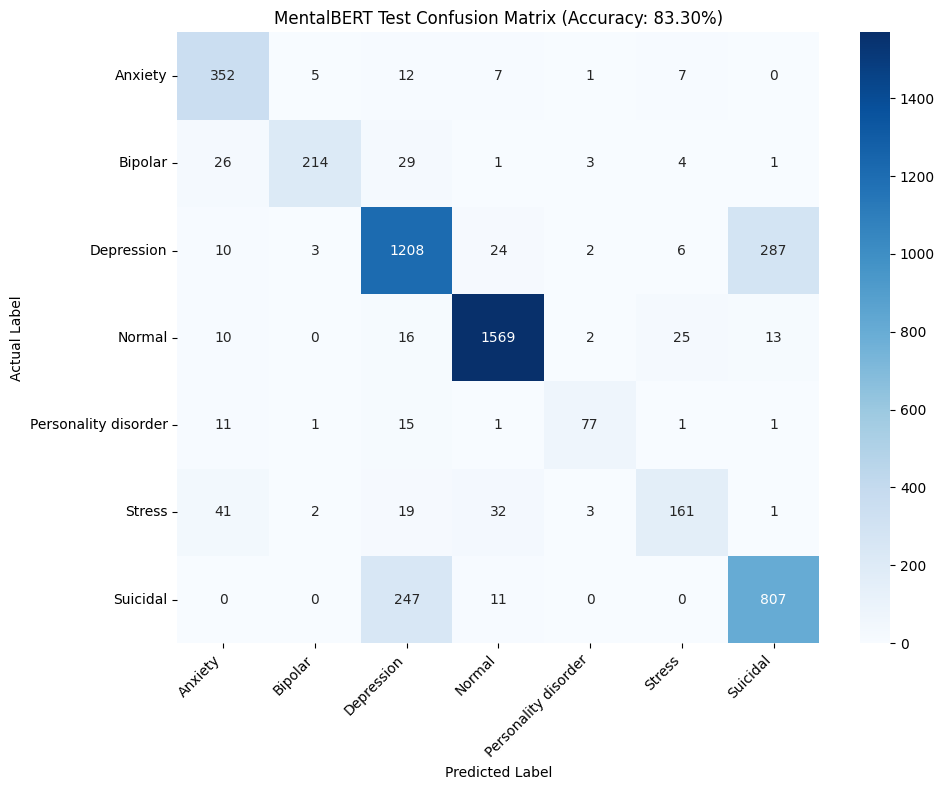


EVALUATION ARTIFACTS SAVED SUCCESSFULLY
Metrics: /content/drive/MyDrive/MINDTRACE_checkpoints/evaluation_summary_text.json
Confusion Matrix: /content/drive/MyDrive/MINDTRACE_checkpoints/confusion_matrix_text.png

TEST EVALUATION COMPLETED.


In [22]:

# CELL 8 — Held-Out Test Evaluation & Metrics Export

import os
import json
import shutil
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. DEVICE CONFIGURATION
# --------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Evaluation device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 2. GOOGLE DRIVE CHECK
# --------------------------------------------------

DRIVE_DIR = "/content/drive/MyDrive/MINDTRACE_checkpoints"

if not os.path.isdir("/content/drive/MyDrive"):
    raise RuntimeError("Google Drive is not mounted. Mount Drive first.")

best_checkpoint = os.path.join(DRIVE_DIR, "text_model_best.pt")
final_checkpoint = os.path.join(DRIVE_DIR, "text_model_final.pt")

if os.path.exists(best_checkpoint):
    eval_ckpt = best_checkpoint
elif os.path.exists(final_checkpoint):
    eval_ckpt = final_checkpoint
else:
    raise FileNotFoundError("No trained checkpoint found in Google Drive.")

# --------------------------------------------------
# 3. RESTORE MODEL ARCHITECTURE AND WEIGHTS
# --------------------------------------------------

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(class_names),
    token=hf_token
)

checkpoint = torch.load(eval_ckpt, map_location="cpu", weights_only=True)
model.load_state_dict(checkpoint)

model.to(device)
model.eval()

print("\nLoaded checkpoint:", eval_ckpt)
print("Model restored successfully.")

# --------------------------------------------------
# 4. HELD-OUT TEST EVALUATION
# --------------------------------------------------

all_preds = []
all_labels = []

use_amp = device.type == "cuda"

with torch.inference_mode():
    for batch in tqdm(test_loader, desc="Evaluating test set"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        preds = outputs.logits.argmax(dim=1).cpu()

        all_preds.extend(preds.tolist())
        all_labels.extend(batch["labels"].tolist())

print("\nEvaluation completed.")
print("Total test samples:", len(all_labels))

# --------------------------------------------------
# 5. CALCULATE METRICS
# --------------------------------------------------

test_acc = accuracy_score(all_labels, all_preds)

macro_f1 = f1_score(
    all_labels, all_preds, average="macro"
)

weighted_f1 = f1_score(
    all_labels, all_preds, average="weighted"
)

report_dict = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

suicidal_recall = report_dict.get("Suicidal", {}).get("recall", 0.0)

print("\n" + "=" * 60)
print("MENTALBERT — FINAL TEST EVALUATION")
print("=" * 60)

print(f"Test Accuracy         : {test_acc*100:.2f}% ({test_acc:.4f})")
print(f"Macro F1              : {macro_f1*100:.2f}% ({macro_f1:.4f})")
print(f"Weighted F1           : {weighted_f1*100:.2f}% ({weighted_f1:.4f})")
print(f"Suicidal-Class Recall : {suicidal_recall*100:.2f}% ({suicidal_recall:.4f})")

print("\nClassification Report:")

print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    zero_division=0
))

# --------------------------------------------------
# 6. SAVE METRICS
# --------------------------------------------------

eval_summary = {
    "test_accuracy": float(test_acc),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "suicidal_recall": float(suicidal_recall),
    "classification_report": report_dict
}

json_path = "evaluation_summary_text.json"

with open(json_path, "w") as f:
    json.dump(eval_summary, f, indent=2)

# --------------------------------------------------
# 7. CONFUSION MATRIX
# --------------------------------------------------

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    f"MentalBERT Test Confusion Matrix (Accuracy: {test_acc*100:.2f}%)"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = "confusion_matrix_text.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 8. EXPORT EVERYTHING TO GOOGLE DRIVE
# --------------------------------------------------

shutil.copy(
    json_path,
    os.path.join(DRIVE_DIR, json_path)
)

shutil.copy(
    cm_path,
    os.path.join(DRIVE_DIR, cm_path)
)

print("\n" + "=" * 60)
print("EVALUATION ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 60)

print("Metrics:", os.path.join(DRIVE_DIR, json_path))
print("Confusion Matrix:", os.path.join(DRIVE_DIR, cm_path))

print("\nTEST EVALUATION COMPLETED.")


In [23]:
# CELL 9 — Automatic Browser Download for Local Placement
try:
    from google.colab import files
    print('Triggering automatic browser download for text_model_final.pt (~438 MB)...')
    files.download('text_model_final.pt')
    files.download('evaluation_summary_text.json')
    files.download('confusion_matrix_text.png')
    print('Download started! Move text_model_final.pt to your local repo: models/text/text_model_final.pt')
except Exception as e:
    print(f'Note on manual download: {e}')
    print('All files are preserved in current working directory and Google Drive.')

Triggering automatic browser download for text_model_final.pt (~438 MB)...
Note on manual download: Cannot find file: text_model_final.pt
All files are preserved in current working directory and Google Drive.


In [24]:

# MINDTRACE — Export Best Trained MentalBERT Model

import os
import json
import torch
import shutil
from transformers import AutoTokenizer

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------

DRIVE_DIR = "/content/drive/MyDrive/MINDTRACE_checkpoints"

CHECKPOINT_PATH = os.path.join(
    DRIVE_DIR, "text_model_best.pt"
)

EXPORT_DIR = os.path.join(
    DRIVE_DIR, "mentalbert_best_export"
)

os.makedirs(EXPORT_DIR, exist_ok=True)

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Best checkpoint not found: {CHECKPOINT_PATH}"
    )

print("Checkpoint found:", CHECKPOINT_PATH)

# --------------------------------------------------
# 2. RESTORE BEST CHECKPOINT
# --------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint)
model.cpu()
model.eval()

print("Best trained weights restored successfully.")

# --------------------------------------------------
# 3. CONFIGURE CLASS LABELS
# --------------------------------------------------

model.config.num_labels = len(class_names)

model.config.id2label = {
    i: str(label)
    for i, label in enumerate(class_names)
}

model.config.label2id = {
    str(label): i
    for i, label in enumerate(class_names)
}

# --------------------------------------------------
# 4. LOAD AND SAVE TOKENIZER
# --------------------------------------------------

try:
    tokenizer
except NameError:
    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )

# --------------------------------------------------
# 5. EXPORT MODEL AND TOKENIZER
# --------------------------------------------------

model.save_pretrained(
    EXPORT_DIR,
    safe_serialization=True
)

tokenizer.save_pretrained(EXPORT_DIR)

# Save additional metadata
metadata = {
    "model_name": MODEL_NAME,
    "architecture": "BERT Sequence Classification",
    "num_labels": len(class_names),
    "class_names": list(class_names),
    "max_length": 128,
    "selected_checkpoint": "text_model_best.pt",
    "selected_epoch": 2,
    "test_accuracy": 0.8330,
    "macro_f1": 0.8088,
    "weighted_f1": 0.8325,
    "suicidal_recall": 0.7577
}

with open(
    os.path.join(EXPORT_DIR, "training_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

# --------------------------------------------------
# 6. VERIFY EXPORTED FILES
# --------------------------------------------------

print("\n" + "=" * 55)
print("MENTALBERT EXPORT COMPLETED")
print("=" * 55)

total_size = 0

for filename in sorted(os.listdir(EXPORT_DIR)):
    filepath = os.path.join(EXPORT_DIR, filename)

    if os.path.isfile(filepath):
        size = os.path.getsize(filepath)
        total_size += size

        print(
            f"{filename:<35} "
            f"{size / (1024**2):.2f} MB"
        )

print("-" * 55)
print(f"Total export size: {total_size / (1024**2):.2f} MB")
print("Export location:", EXPORT_DIR)

# --------------------------------------------------
# 7. CREATE ZIP FOR LOCAL DOWNLOAD
# --------------------------------------------------

ZIP_PATH = "/content/mentalbert_best_export"

shutil.make_archive(
    ZIP_PATH,
    "zip",
    EXPORT_DIR
)

print("\nZIP created:", ZIP_PATH + ".zip")
print("Ready to download.")


Checkpoint found: /content/drive/MyDrive/MINDTRACE_checkpoints/text_model_best.pt
Best trained weights restored successfully.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


MENTALBERT EXPORT COMPLETED
config.json                         0.00 MB
model.safetensors                   417.68 MB
tokenizer.json                      0.68 MB
tokenizer_config.json               0.00 MB
training_metadata.json              0.00 MB
-------------------------------------------------------
Total export size: 418.37 MB
Export location: /content/drive/MyDrive/MINDTRACE_checkpoints/mentalbert_best_export

ZIP created: /content/mentalbert_best_export.zip
Ready to download.


In [25]:
from google.colab import files
files.download("/content/mentalbert_best_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

# Restore trained MentalBERT model without training

import torch
import os
from transformers import AutoModelForSequenceClassification

DRIVE_DIR = "/content/drive/MyDrive/MINDTRACE_checkpoints"
best_checkpoint = os.path.join(DRIVE_DIR, "text_model_best.pt")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(class_names),
    token=hf_token
)

model.to(device)

if not os.path.exists(best_checkpoint):
    raise FileNotFoundError(f"Checkpoint not found: {best_checkpoint}")

checkpoint = torch.load(best_checkpoint, map_location=device)
model.load_state_dict(checkpoint)

model.eval()

print("MentalBERT restored successfully.")
print("Device:", device)
print("Classes:", class_names)
print("Ready for held-out test evaluation.")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those 

MentalBERT restored successfully.
Device: cpu
Classes: ['Anxiety', 'Bipolar', 'Depression', 'Normal', 'Personality disorder', 'Stress', 'Suicidal']
Ready for held-out test evaluation.


In [17]:

import torch
import os

# Recreate device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Evaluation device:", device)

# Move the already-loaded model to the device
model = model.to(device)

# Load the trained best checkpoint from Google Drive
best_checkpoint = "/content/drive/MyDrive/MINDTRACE_checkpoints/text_model_best.pt"

if not os.path.exists(best_checkpoint):
    raise FileNotFoundError(best_checkpoint)

checkpoint = torch.load(best_checkpoint, map_location=device)
model.load_state_dict(checkpoint)

model.eval()

print("Best trained checkpoint restored successfully.")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Ready for evaluation.")


Evaluation device: cpu
Best trained checkpoint restored successfully.
GPU: CPU
Ready for evaluation.
